# Loan Approval Machine Learning Model

In [1]:
# importing the Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
# importing the Data

df  = pd.read_csv('loan_data.csv')

In [3]:
# check the info and shape of the data

print(f"Shape of the data is : {df.shape}")

print("Info of our Data : ")

df.info()

Shape of the data is : (45000, 14)
Info of our Data : 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 

In [10]:
# Descriubing the Data

df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,45000.0,27.764178,6.045108,20.00,24.00,26.00,30.00,144.00
person_income,45000.0,80319.053222,80422.498632,8000.00,47204.00,67048.00,95789.25,7200766.00
person_emp_exp,45000.0,5.410333,6.063532,0.00,1.00,4.00,8.00,125.00
loan_amnt,45000.0,9583.157556,6314.886691,500.00,5000.00,8000.00,12237.25,35000.00
loan_int_rate,45000.0,11.006606,2.978808,5.42,8.59,11.01,12.99,20.00
loan_percent_income,45000.0,0.139725,0.087212,0.00,0.07,0.12,0.19,0.66
cb_person_cred_hist_length,45000.0,5.867489,3.879702,2.00,3.00,4.00,8.00,30.00
credit_score,45000.0,632.608756,50.435865,390.00,601.00,640.00,670.00,850.00
loan_status,45000.0,0.222222,0.415744,0.00,0.00,0.00,0.00,1.00


In [7]:
# Describing the data including Object

df.describe(include = "object").T

,count,unique,top,freq
person_gender,45000,2,male,24841
person_education,45000,5,Bachelor,13399
person_home_ownership,45000,4,RENT,23443
loan_intent,45000,6,EDUCATION,9153
previous_loan_defaults_on_file,45000,2,Yes,22858


## Data Cleaning and Processing

In [ ]:
# Checking the detailed info of the data

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(df["loan_status"].value_counts())
print("\nTarget percentages:")
print(df["loan_status"].value_counts(normalize=True) * 100)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nAge anomalies:")
print(df.loc[df["person_age"] > 100,
             ["person_age", "person_income"]])

print("\nEmployment experience anomalies:")
print(df.loc[
    df["person_emp_exp"] > df["person_age"] - 18,
    ["person_age", "person_emp_exp"]
])

print("\nExtreme income records:")
print(df.nlargest(10, "person_income")[
    ["person_age", "person_income", "loan_status"]
])

Dataset shape: (45000, 14)

Target distribution:
loan_status
0    35000
1    10000
Name: count, dtype: int64

Target percentages:
loan_status
0    77.777778
1    22.222222
Name: proportion, dtype: float64

Duplicate rows: 0

Age anomalies:
       person_age  person_income
81          144.0       300616.0
183         144.0       241424.0
575         123.0        97140.0
747         123.0        94723.0
32297       144.0      7200766.0
37930       116.0      5545545.0
38113       109.0      5556399.0

Employment experience anomalies:
Empty DataFrame
Columns: [person_age, person_emp_exp]
Index: []

Extreme income records:
       person_age  person_income  loan_status
32297       144.0      7200766.0            0
38113       109.0      5556399.0            0
37930       116.0      5545545.0            0
30049        42.0      2448661.0            0
32546        60.0      2280980.0            0
32497        63.0      2139143.0            0
37175        42.0      2012954.0            0
41288

## _First we have 144 Age of the Person but its come to notice greater aged person loan not approved, hence it ok_
## _Second the Income is showing very high but Loan amountis under 10k for same, but loan not approved for that case hence itis ok_

In [13]:

# Missing values
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})
display(missing.sort_values("Missing_Count", ascending=False))

# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Unique values
print("\nUnique values per column:")
display(df.nunique().sort_values(ascending=False))

# Check data types
print("\nData types:")
display(df.dtypes)

# Check infinite values in numerical columns
numeric_df = df.select_dtypes(include=np.number)
print(
    "Infinite values:",
    np.isinf(numeric_df.to_numpy()).sum()
)


,Missing_Count,Missing_Percentage
person_age,0,0.0
person_gender,0,0.0
person_education,0,0.0
person_income,0,0.0
person_emp_exp,0,0.0
person_home_ownership,0,0.0
loan_amnt,0,0.0
loan_intent,0,0.0
loan_int_rate,0,0.0
loan_percent_income,0,0.0


Duplicate rows: 0

Unique values per column:


person_income                     33989
loan_amnt                          4483
loan_int_rate                      1302
credit_score                        340
loan_percent_income                  64
person_emp_exp                       63
person_age                           60
cb_person_cred_hist_length           29
loan_intent                           6
person_education                      5
person_home_ownership                 4
person_gender                         2
previous_loan_defaults_on_file        2
loan_status                           2
dtype: int64


Data types:


person_age                        float64
person_gender                      object
person_education                   object
person_income                     float64
person_emp_exp                      int64
person_home_ownership              object
loan_amnt                         float64
loan_intent                        object
loan_int_rate                     float64
loan_percent_income               float64
cb_person_cred_hist_length        float64
credit_score                        int64
previous_loan_defaults_on_file     object
loan_status                         int64
dtype: object

Infinite values: 0


## Exploratory Data Analysis EDA

Target value counts:


loan_status
0    35000
1    10000
Name: count, dtype: int64


Target percentages:


loan_status
0    77.78
1    22.22
Name: proportion, dtype: float64

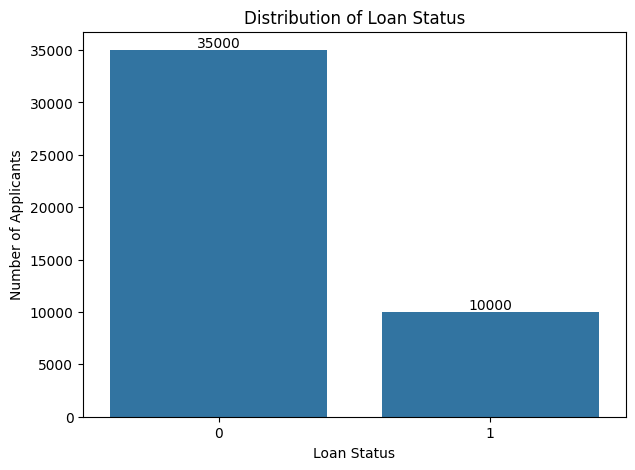

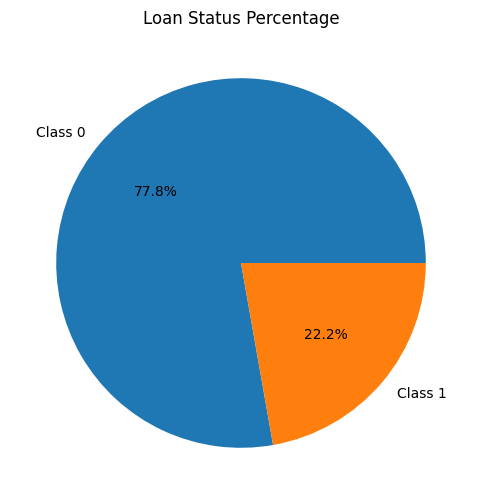

In [12]:

target = "loan_status"

print("Target value counts:")
display(df[target].value_counts().sort_index())

print("\nTarget percentages:")
display(
    (df[target].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df, x=target)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.show()

# Optional pie chart
df[target].value_counts().sort_index().plot(
    kind="pie",
    autopct="%1.1f%%",
    labels=["Class 0", "Class 1"],
    figsize=(6, 6)
)
plt.title("Loan Status Percentage")
plt.ylabel("")
plt.show()


In [14]:

target = "loan_status"

num_cols = (
    df.select_dtypes(include=np.number)
      .columns.drop(target, errors="ignore")
      .tolist()
)

cat_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", num_cols)
print("\nCategorical features:", cat_cols)
print("\nNumerical feature count:", len(num_cols))
print("Categorical feature count:", len(cat_cols))


Numerical features: ['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']

Categorical features: ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']

Numerical feature count: 8
Categorical feature count: 5


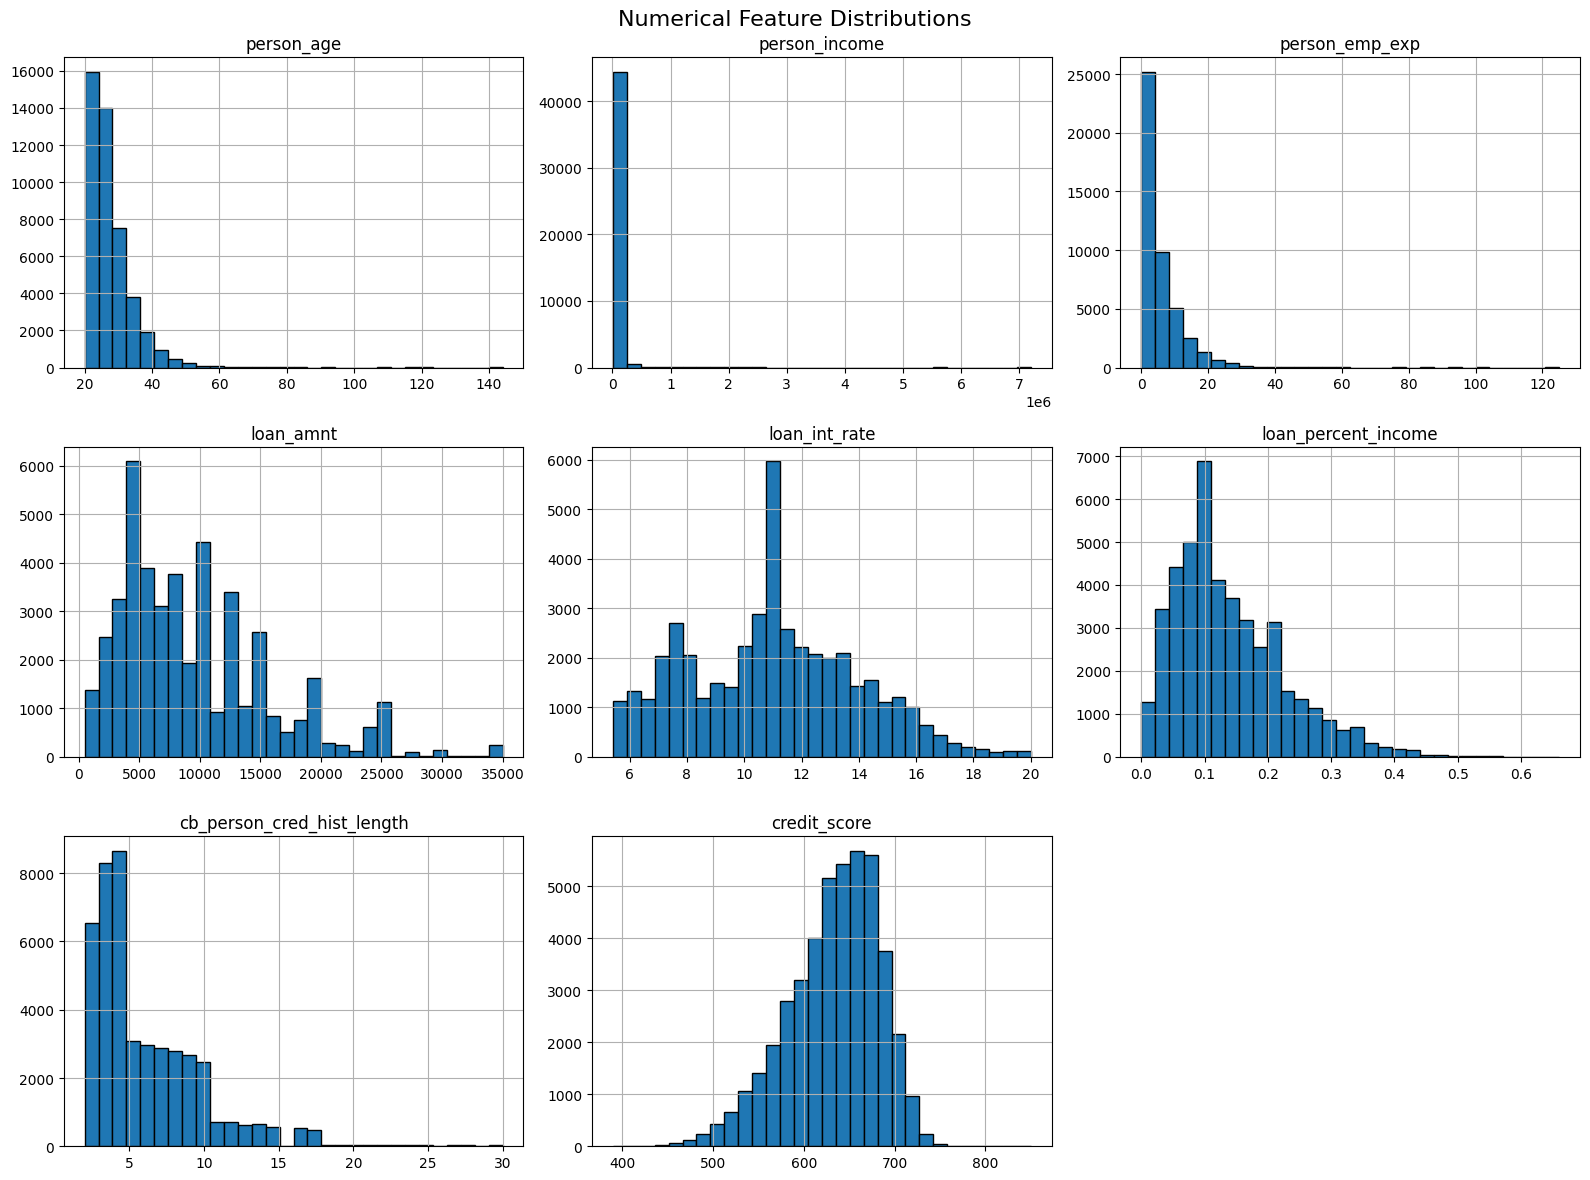

,Skewness
person_income,34.137583
person_emp_exp,2.594917
person_age,2.548154
cb_person_cred_hist_length,1.631720
loan_amnt,1.179731
loan_percent_income,1.034512
loan_int_rate,0.213784
credit_score,-0.610261


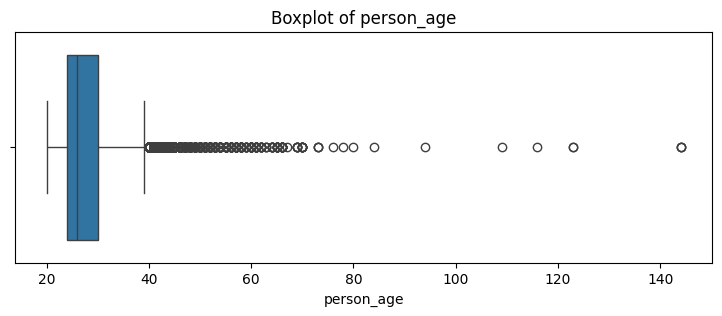

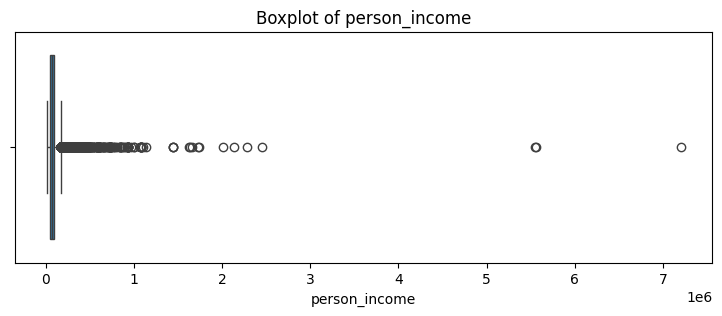

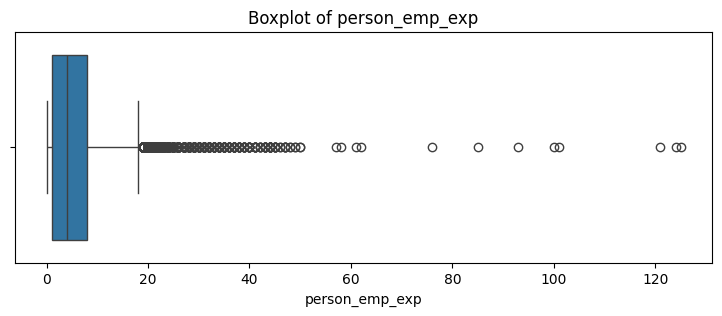

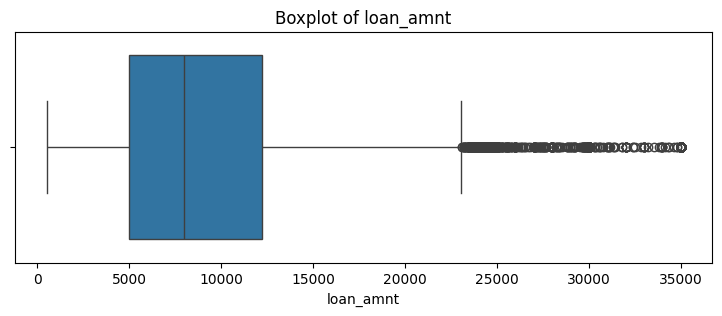

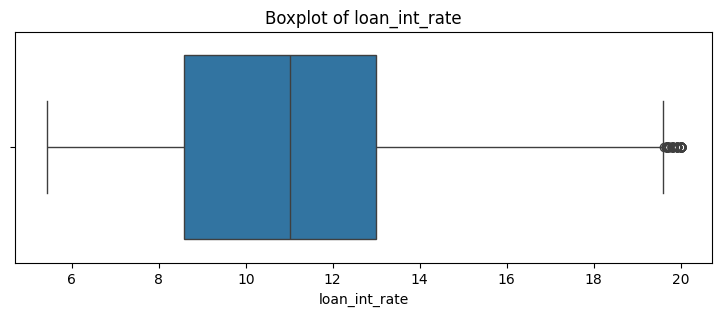

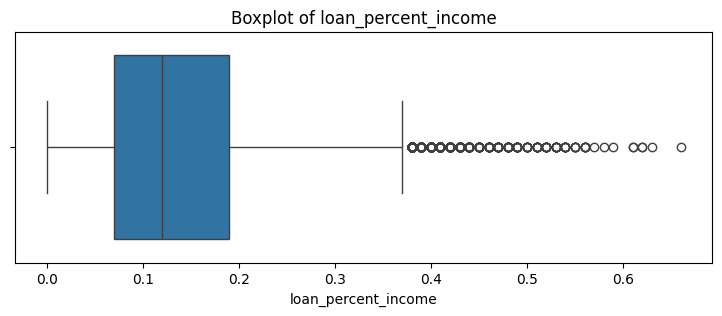

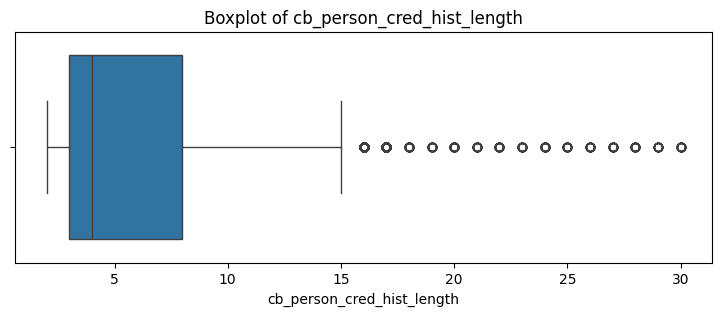

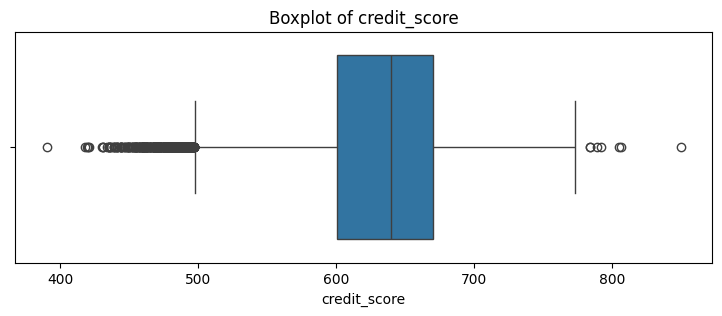

In [ ]:
# Analysis of Numerical colums
# Histograms
df[num_cols].hist(
    bins=30,
    figsize=(16, 12),
    edgecolor="black"
)

plt.suptitle("Numerical Feature Distributions", fontsize=16)
plt.tight_layout()
plt.show()

# Skewness
skewness = df[num_cols].skew().sort_values(
    ascending=False
)

display(skewness.to_frame("Skewness"))

# Boxplots
for col in num_cols:
    plt.figure(figsize=(9, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()



Value counts for person_gender:


,Count
person_gender,
male,24841
female,20159


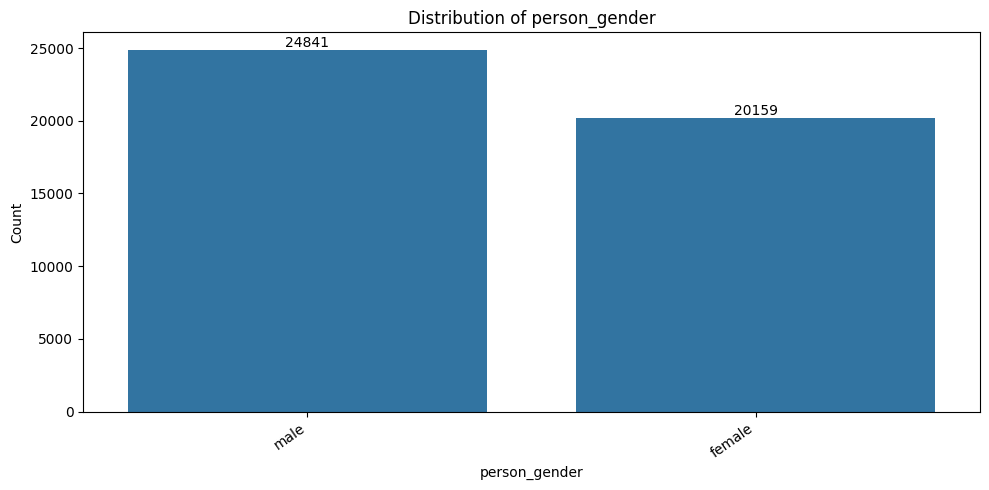


Value counts for person_education:


,Count
person_education,
Bachelor,13399
Associate,12028
High School,11972
Master,6980
Doctorate,621


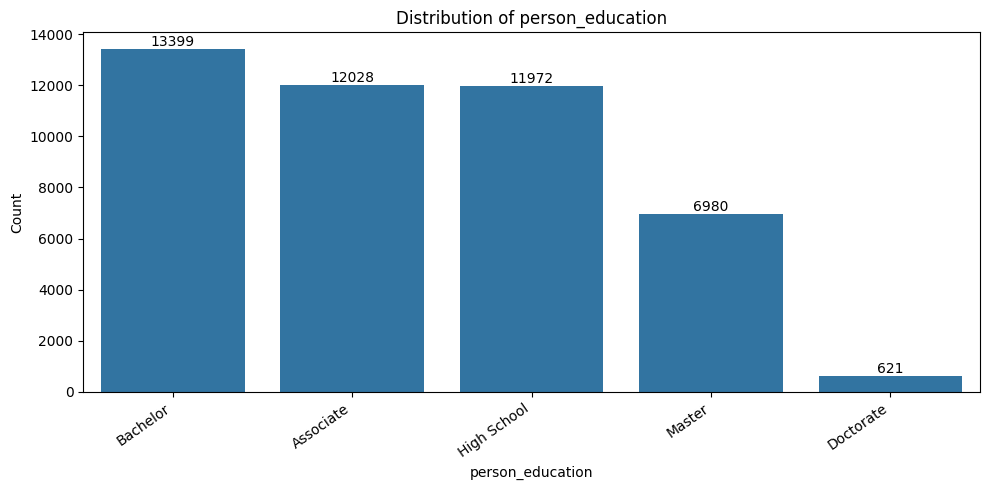


Value counts for person_home_ownership:


,Count
person_home_ownership,
RENT,23443
MORTGAGE,18489
OWN,2951
OTHER,117


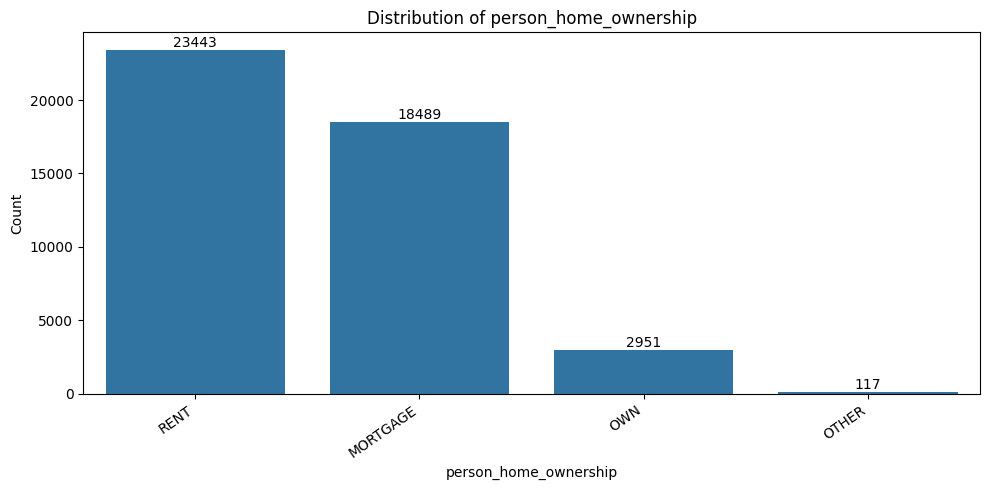


Value counts for loan_intent:


,Count
loan_intent,
EDUCATION,9153
MEDICAL,8548
VENTURE,7819
PERSONAL,7552
DEBTCONSOLIDATION,7145
HOMEIMPROVEMENT,4783


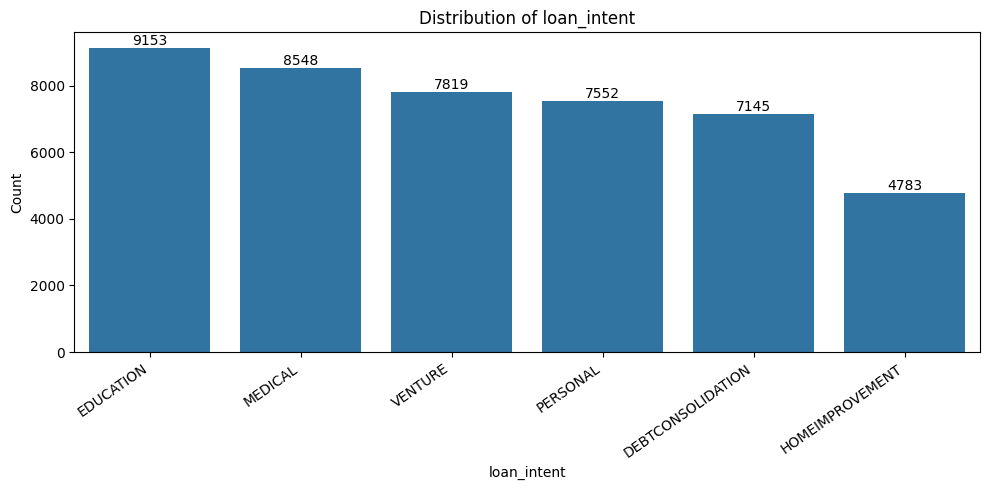


Value counts for previous_loan_defaults_on_file:


,Count
previous_loan_defaults_on_file,
Yes,22858
No,22142


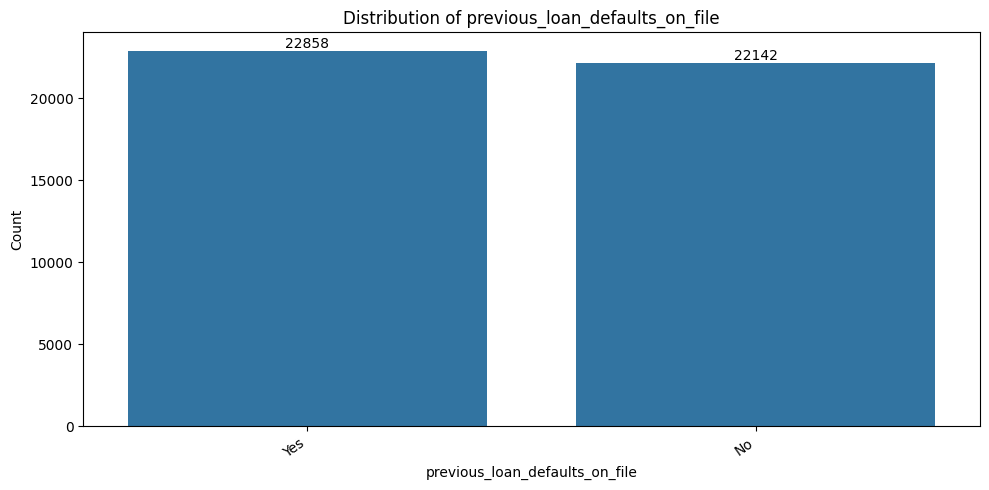

In [19]:

for col in cat_cols:
    print(f"\nValue counts for {col}:")
    display(df[col].value_counts(dropna=False).to_frame("Count"))

    plt.figure(figsize=(10, 5))
    order = df[col].value_counts().index

    ax = sns.countplot(
        data=df,
        x=col,
        order=order,
    )

    ax.bar_label(ax.containers[0])
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


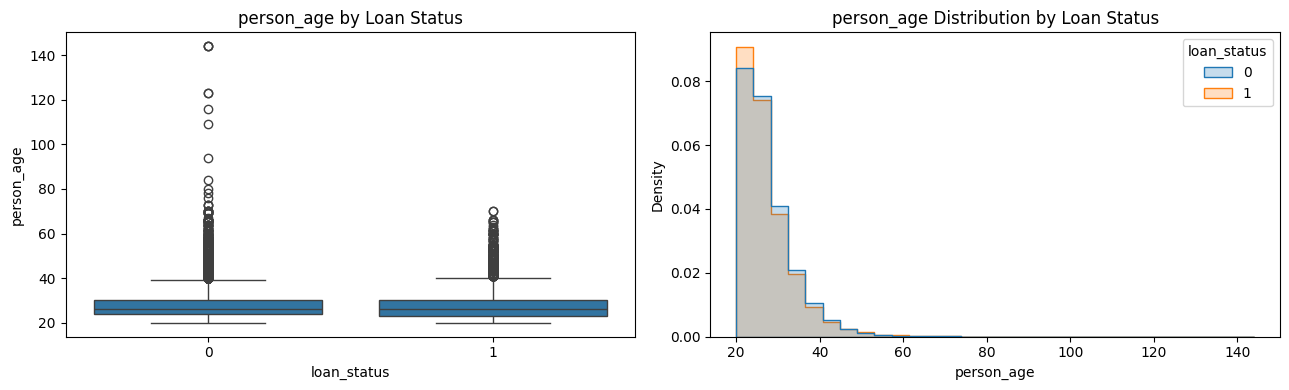

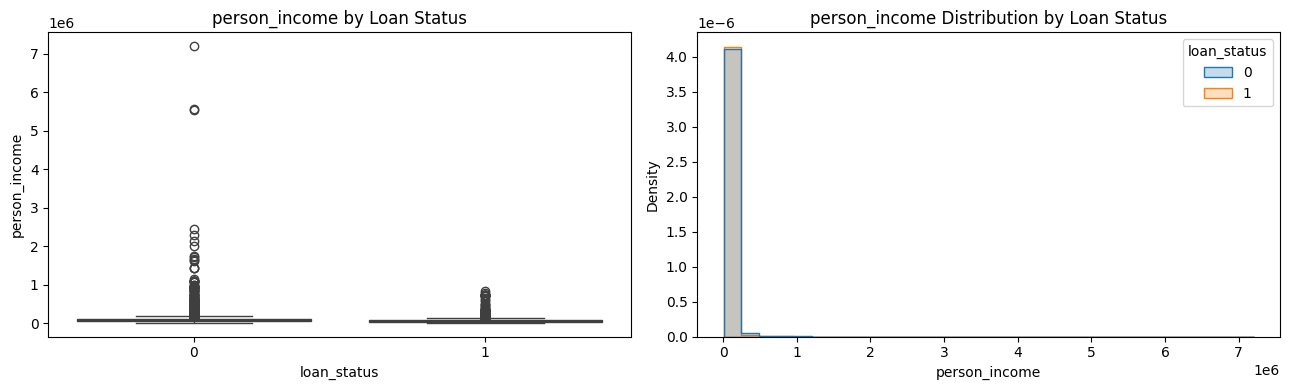

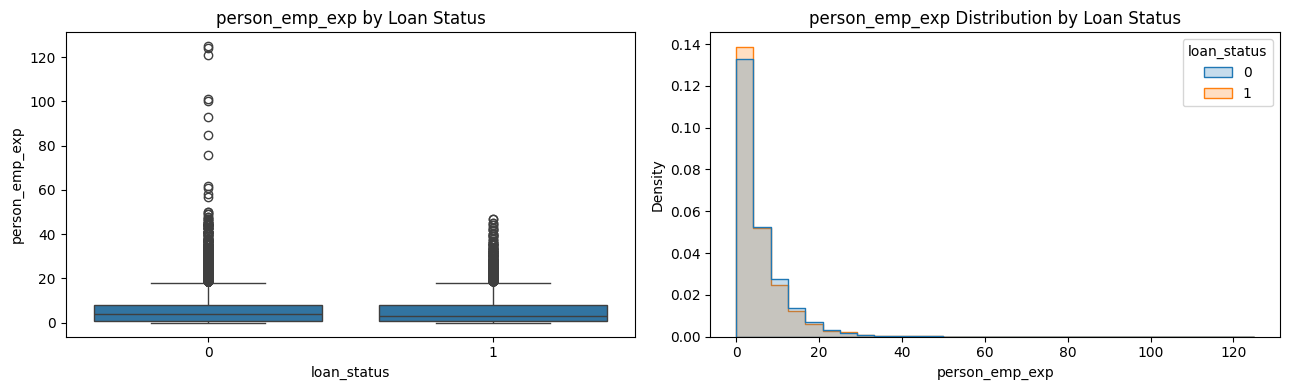

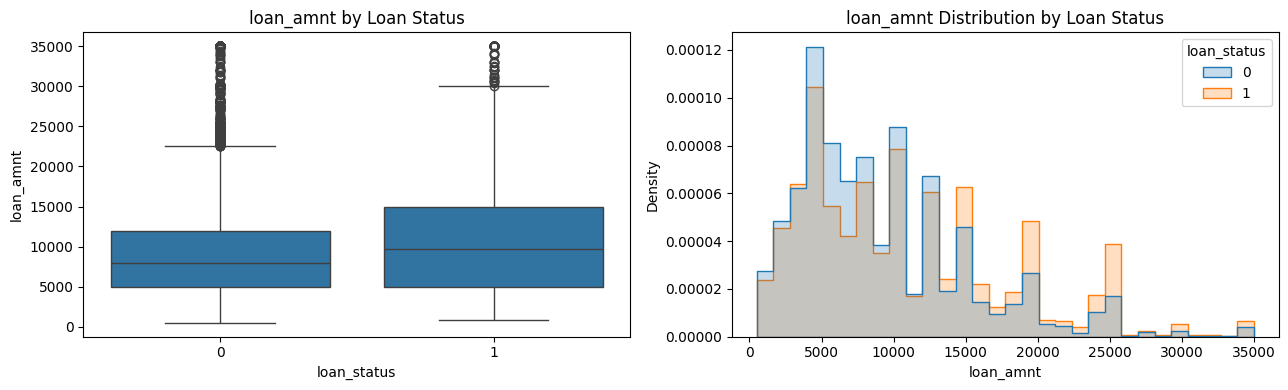

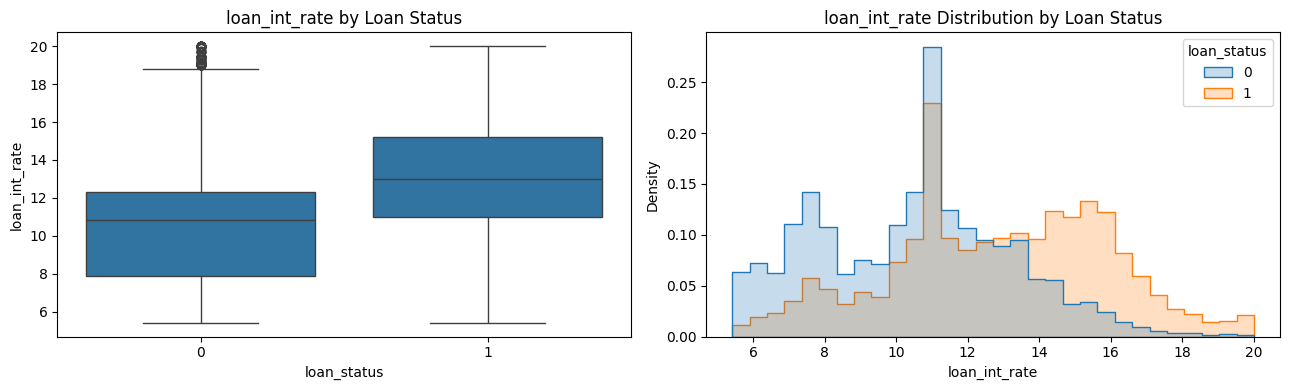

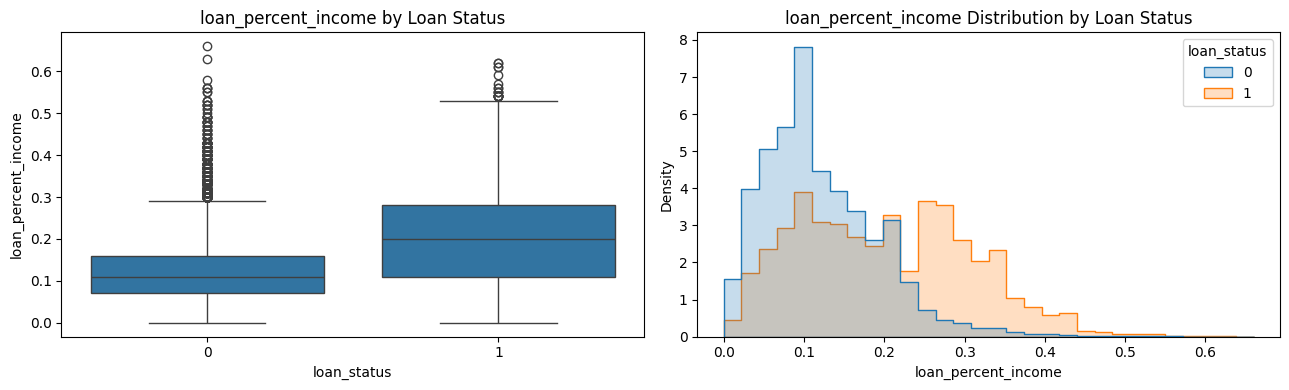

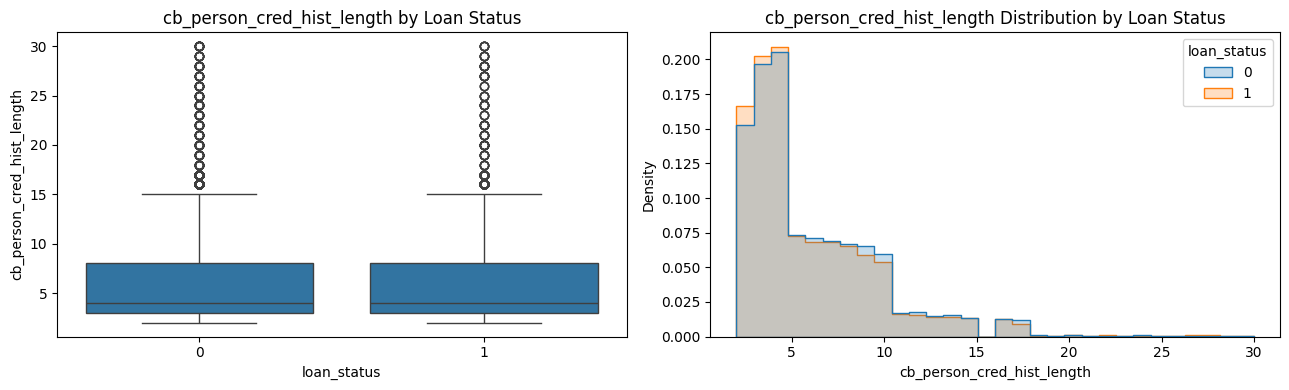

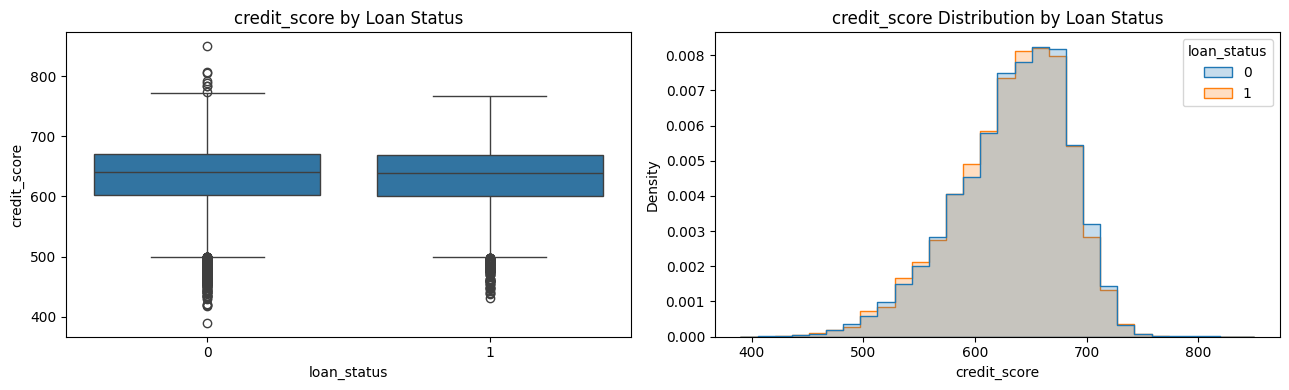

In [20]:

for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    sns.boxplot(
        data=df,
        x=target,
        y=col,
        ax=axes[0]
    )
    axes[0].set_title(f"{col} by Loan Status")

    sns.histplot(
        data=df,
        x=col,
        hue=target,
        bins=30,
        element="step",
        stat="density",
        common_norm=False,
        ax=axes[1]
    )
    axes[1].set_title(f"{col} Distribution by Loan Status")

    plt.tight_layout()
    plt.show()


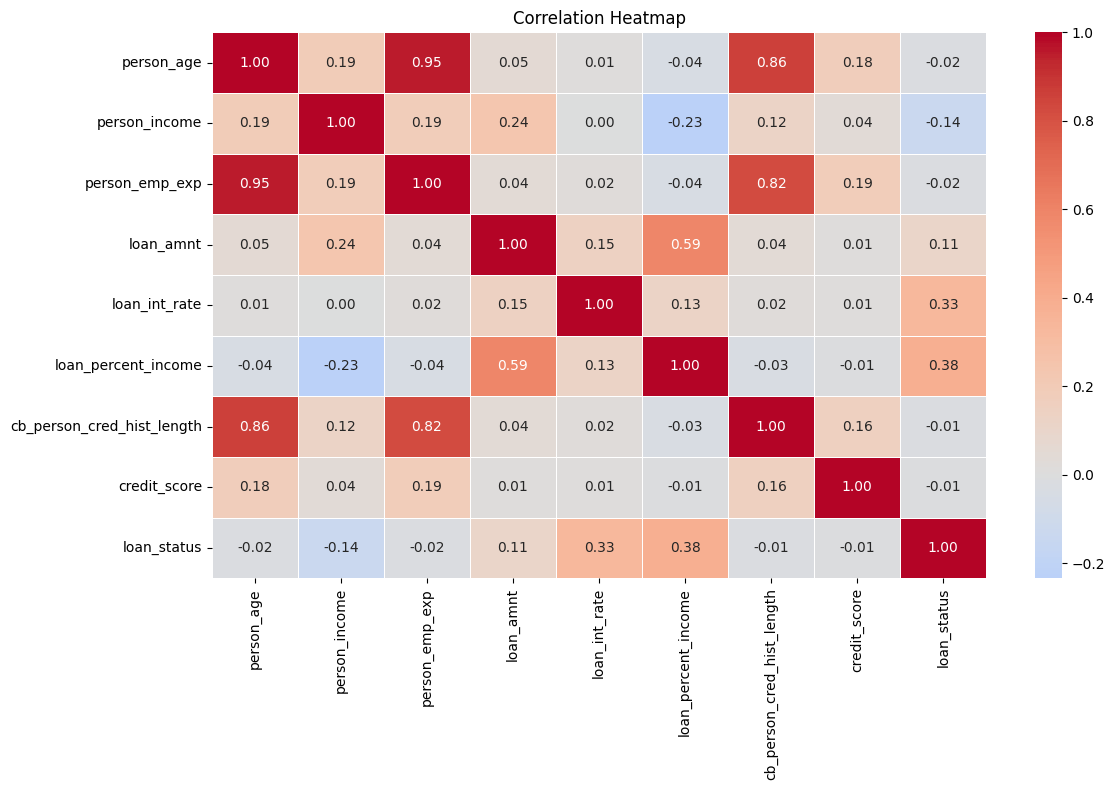

Features most correlated with target:


,Correlation with loan_status
loan_percent_income,0.384880
loan_int_rate,0.332005
person_income,-0.135808
loan_amnt,0.107714
person_age,-0.021476
person_emp_exp,-0.020481
cb_person_cred_hist_length,-0.014851
credit_score,-0.007647


In [ ]:
# Cheacking the Correlation Matrix for the numerical cols

corr = df[num_cols + [target]].corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("Features most correlated with target:")
display(
    corr[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
    .to_frame("Correlation with loan_status")
)


,count,mean,std,min,25%,50%,75%,max
Existing_Ratio,45000.0,0.139725,0.087212,0.000000,0.070000,0.120000,0.190000,0.660000
Recomputed_Ratio,45000.0,0.139748,0.087166,0.000658,0.073558,0.121655,0.188144,0.664186


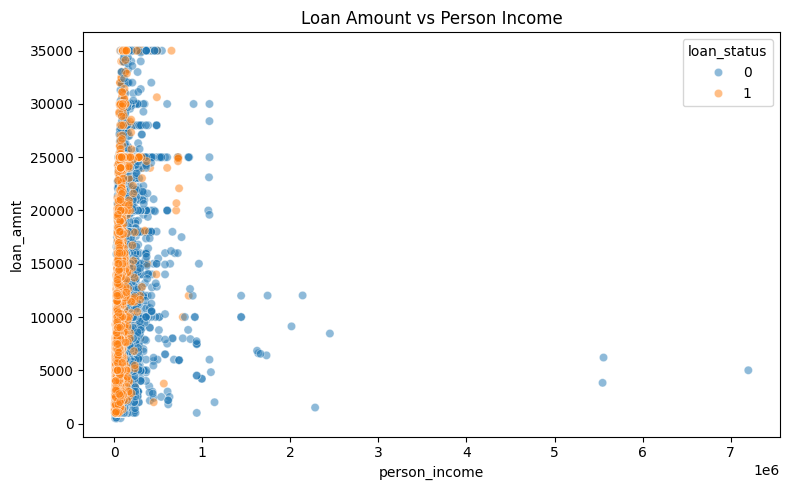

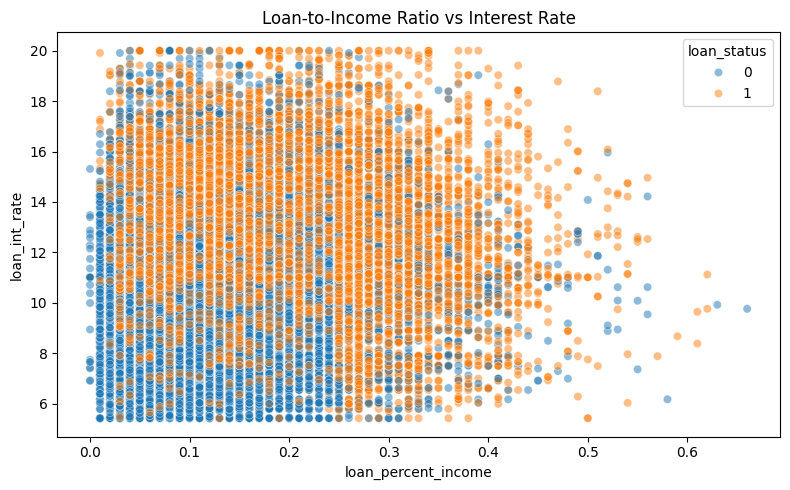

In [22]:

# Compare existing loan_percent_income with recomputed ratio.
# Confirm the units and definition of person_income first.
ratio = df["loan_amnt"] / df["person_income"].replace(0, np.nan)

display(
    pd.DataFrame({
        "Existing_Ratio": df["loan_percent_income"],
        "Recomputed_Ratio": ratio
    }).describe().T
)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="person_income",
    y="loan_amnt",
    hue=target,
    alpha=0.5
)
plt.title("Loan Amount vs Person Income")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="loan_percent_income",
    y="loan_int_rate",
    hue=target,
    alpha=0.5
)
plt.title("Loan-to-Income Ratio vs Interest Rate")
plt.tight_layout()
plt.show()


In [23]:

eda_summary = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100,
    "Unique_Values": df.nunique(),
})

display(eda_summary)

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Target balance:")
print(df[target].value_counts(normalize=True).mul(100).round(2))

print("\nEDA completed.")


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
person_age,float64,0,0.0,60
person_gender,object,0,0.0,2
person_education,object,0,0.0,5
person_income,float64,0,0.0,33989
person_emp_exp,int64,0,0.0,63
person_home_ownership,object,0,0.0,4
loan_amnt,float64,0,0.0,4483
loan_intent,object,0,0.0,6
loan_int_rate,float64,0,0.0,1302
loan_percent_income,float64,0,0.0,64


Dataset shape: (45000, 14)
Duplicate rows: 0
Target balance:
loan_status
0    77.78
1    22.22
Name: proportion, dtype: float64

EDA completed.


## Moving to Featchure Engineering

In [24]:
# First Deviding the data into train and test 

X = df.drop(columns=["loan_status"])
y = df["loan_status"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (45000, 13)
Target shape: (45000,)


In [25]:
# Spliting the data into train and test

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (36000, 13)
X_test: (9000, 13)
y_train: (36000,)
y_test: (9000,)


In [26]:
# Checking the Categorical cols 


cat_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

num_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical columns:", cat_cols)
print("Numerical columns:", num_cols)

Categorical columns: ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']
Numerical columns: ['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']


In [27]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            cat_cols
        )
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (36000, 27)
Encoded testing shape: (9000, 27)


In [28]:
feature_names = preprocessor.get_feature_names_out()

print("Total encoded features:", len(feature_names))
print("\nEncoded feature names:")

print(feature_names.tolist())

Total encoded features: 27

Encoded feature names:
['cat__person_gender_female', 'cat__person_gender_male', 'cat__person_education_Associate', 'cat__person_education_Bachelor', 'cat__person_education_Doctorate', 'cat__person_education_High School', 'cat__person_education_Master', 'cat__person_home_ownership_MORTGAGE', 'cat__person_home_ownership_OTHER', 'cat__person_home_ownership_OWN', 'cat__person_home_ownership_RENT', 'cat__loan_intent_DEBTCONSOLIDATION', 'cat__loan_intent_EDUCATION', 'cat__loan_intent_HOMEIMPROVEMENT', 'cat__loan_intent_MEDICAL', 'cat__loan_intent_PERSONAL', 'cat__loan_intent_VENTURE', 'cat__previous_loan_defaults_on_file_No', 'cat__previous_loan_defaults_on_file_Yes', 'remainder__person_age', 'remainder__person_income', 'remainder__person_emp_exp', 'remainder__loan_amnt', 'remainder__loan_int_rate', 'remainder__loan_percent_income', 'remainder__cb_person_cred_hist_length', 'remainder__credit_score']


## Applying the Machine Learnign Models

In [31]:
# Importing the ML Models 



from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train_encoded, y_train)

    y_pred = model.predict(X_test_encoded)
    y_prob = model.predict_proba(X_test_encoded)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)


Training Logistic Regression...


c:\Users\ashis\.ai-navigator\micromamba\envs\cuda\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Training Decision Tree...
Training Random Forest...
Training KNN...
Training XGBoost...


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.9326,0.8937,0.7905,0.8389,0.9781
1,Random Forest,0.9297,0.9028,0.7660,0.8288,0.9746
2,Decision Tree,0.8970,0.7655,0.7735,0.7695,0.8529
3,Logistic Regression,0.8383,0.5863,0.9255,0.7179,0.9453
4,KNN,0.8326,0.6458,0.5460,0.5917,0.8204


In [32]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

lr_model = make_pipeline(
    StandardScaler(with_mean=False),
    LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        random_state=42
    )
)

lr_model.fit(X_train_encoded, y_train)

lr_pred = lr_model.predict(X_test_encoded)

print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.97      0.84      0.90      7000
           1       0.63      0.92      0.75      2000

    accuracy                           0.86      9000
   macro avg       0.80      0.88      0.82      9000
weighted avg       0.90      0.86      0.87      9000



## Checking the Outpur of Model Performance

Leading model: XGBoost
              precision    recall  f1-score   support

     Class 0       0.94      0.97      0.96      7000
     Class 1       0.89      0.79      0.84      2000

    accuracy                           0.93      9000
   macro avg       0.92      0.88      0.90      9000
weighted avg       0.93      0.93      0.93      9000



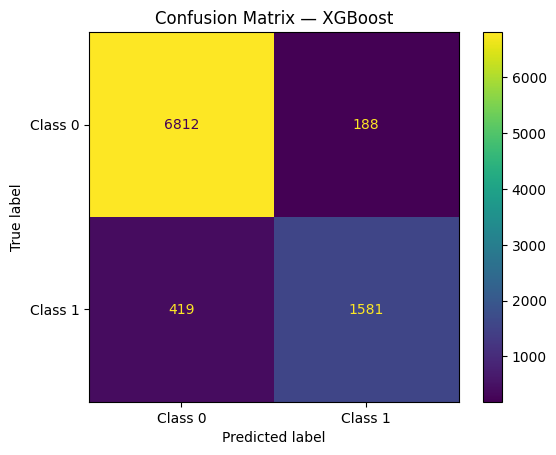

In [33]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]

y_pred_best = best_model.predict(X_test_encoded)

print("Leading model:", best_model_name)
print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=["Class 0", "Class 1"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=["Class 0", "Class 1"]
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

Leading model: Random Forest
              precision    recall  f1-score   support

     Class 0       0.94      0.98      0.96      7000
     Class 1       0.90      0.77      0.83      2000

    accuracy                           0.93      9000
   macro avg       0.92      0.87      0.89      9000
weighted avg       0.93      0.93      0.93      9000



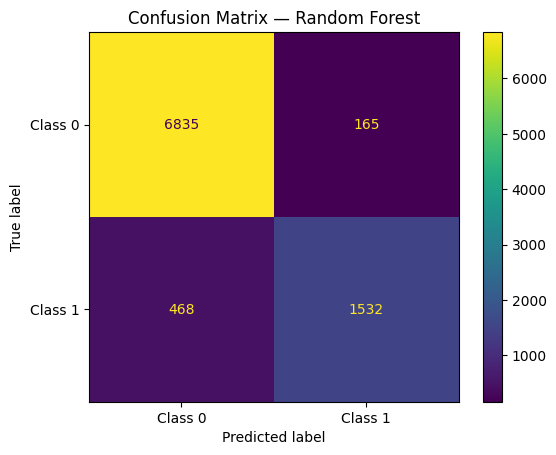

In [34]:
# Checking the Random Forest Classifier Model 
best_model_name = results_df.loc[1, "Model"]
best_model = trained_models[best_model_name]

y_pred_best = best_model.predict(X_test_encoded)

print("Leading model:", best_model_name)
print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=["Class 0", "Class 1"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=["Class 0", "Class 1"]
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

## Checking the Best Perofrmance ML Module in 20 Condition

In [35]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score
)

# Define the model
rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Hyperparameter search space
param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [None, 10, 15, 20, 25],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"],
    "bootstrap": [True]
}

# Search using training data only
rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=20,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

rf_search.fit(X_train_encoded, y_train)

print("Best parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(rf_search.best_score_, 4))

# Evaluate once on the held-out test set
best_rf = rf_search.best_estimator_
y_pred_rf = best_rf.predict(X_test_encoded)
y_prob_rf = best_rf.predict_proba(X_test_encoded)[:, 1]

print("\nTest accuracy:", round(
    accuracy_score(y_test, y_pred_rf), 4
))

print("Test ROC-AUC:", round(
    roc_auc_score(y_test, y_prob_rf), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best parameters:
{'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 25, 'bootstrap': True}

Best cross-validation F1-score:
0.829

Test accuracy: 0.9284
Test ROC-AUC: 0.9748

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      7000
           1       0.86      0.81      0.83      2000

    accuracy                           0.93      9000
   macro avg       0.90      0.89      0.89      9000
weighted avg       0.93      0.93      0.93      9000


Confusion Matrix:
[[6730  270]
 [ 374 1626]]


Top 15 Important Features:


,Feature,Importance
17,cat__previous_loan_defaults_on_file_No,0.2315
18,cat__previous_loan_defaults_on_file_Yes,0.2025
23,remainder__loan_int_rate,0.1247
24,remainder__loan_percent_income,0.1062
20,remainder__person_income,0.0855
22,remainder__loan_amnt,0.0406
26,remainder__credit_score,0.0387
10,cat__person_home_ownership_RENT,0.0291
19,remainder__person_age,0.0211
21,remainder__person_emp_exp,0.0191


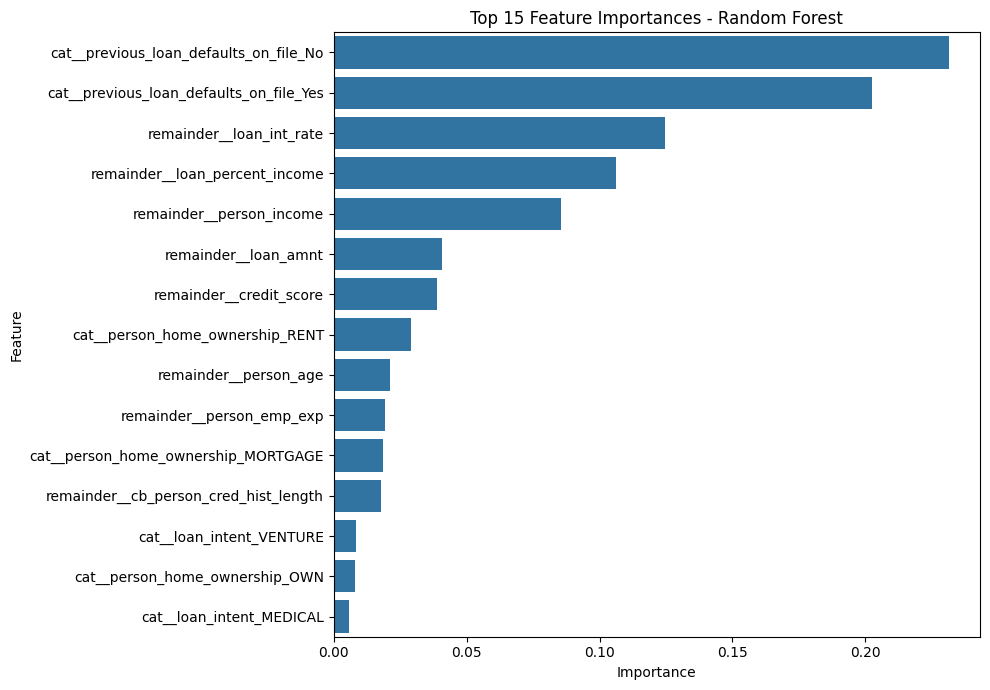

In [36]:



# Feature names after encoding
feature_names = preprocessor.get_feature_names_out()

# Feature importance from tuned Random Forest
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": best_rf.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
display(importance_df.head(15).round(4))

# Visualization
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


,Feature,Importance,Std
17,cat__previous_loan_defaults_on_file_No,0.2921,0.0073
24,remainder__loan_percent_income,0.1470,0.0076
23,remainder__loan_int_rate,0.1345,0.0052
18,cat__previous_loan_defaults_on_file_Yes,0.0998,0.0037
20,remainder__person_income,0.0624,0.0053
10,cat__person_home_ownership_RENT,0.0321,0.0027
26,remainder__credit_score,0.0125,0.0041
13,cat__loan_intent_HOMEIMPROVEMENT,0.0102,0.0014
9,cat__person_home_ownership_OWN,0.0076,0.0014
11,cat__loan_intent_DEBTCONSOLIDATION,0.0055,0.0016


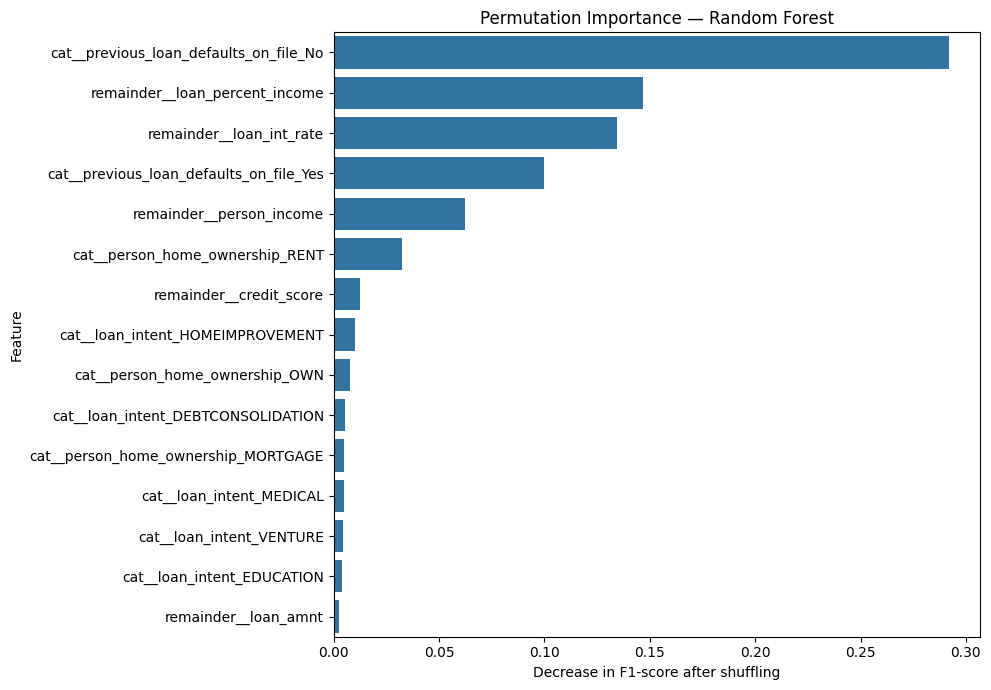

In [37]:

from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score

perm_result = permutation_importance(
    best_rf,
    X_test_encoded,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

perm_df = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values("Importance", ascending=False)

display(perm_df.head(15).round(4))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=perm_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Permutation Importance — Random Forest")
plt.xlabel("Decrease in F1-score after shuffling")
plt.tight_layout()
plt.show()


# Now we are ready to Build Output of our ML Model


In [38]:

import joblib

model_bundle = {
    "model": best_rf,
    "preprocessor": preprocessor,
    "columns": X_train.columns.tolist(),
    "category_options": {
        col: sorted(df[col].dropna().unique().tolist())
        for col in X_train.select_dtypes(
            include=["object", "category"]
        ).columns
    }
}

joblib.dump(model_bundle, "loan_approval_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [ ]:
|